In [1]:
import pandas as pd
import pylab as pl
import numpy as np
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [4]:
import os
df = pd.read_csv("recursos_humanos.csv")
df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [5]:
# 2. Seleccionamos nuestra variable objetivo (y) y las predictoras (X)
# 'left' es la columna que dice si se fue o no
y = df['left']
X = df.drop('left', axis=1) # X es todo el dataframe MENOS la columna 'left'

# 3.  get_dummies
# Esto convertirá todas las columnas de texto (department, salary, etc.) en 0s y 1s
X = pd.get_dummies(X, drop_first=True) 
# (drop_first=True borra la primera columna de cada categoría para evitar redundancia matemática)

# 4. Verificamos que todo sea numérico
print(X.head())

   satisfaction_level  last_evaluation  number_project  average_montly_hours  \
0                0.38             0.53               2                   157   
1                0.80             0.86               5                   262   
2                0.11             0.88               7                   272   
3                0.72             0.87               5                   223   
4                0.37             0.52               2                   159   

   time_spend_company  Work_accident  promotion_last_5years  sales_RandD  \
0                   3              0                      0            0   
1                   6              0                      0            0   
2                   4              0                      0            0   
3                   5              0                      0            0   
4                   3              0                      0            0   

   sales_accounting  sales_hr  sales_management  sales_marketi

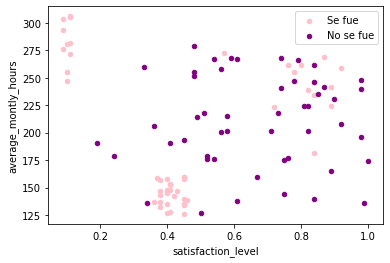

In [6]:
#Graficamos letf según dos variables (satisfaction_level y average_montly_hours)

ax = df[df["left"] == 1][0:50].plot(kind="scatter", x="satisfaction_level", y="average_montly_hours", color="Pink", label="Se fue")
ax = df[df["left"] == 0][0:50].plot(kind="scatter", x="satisfaction_level", y="average_montly_hours", color="Purple", label="No se fue", ax=ax)
plt.show()

In [8]:
#Esta parte me la salto proque ya tenemos todos preparados con pd.get_dummies, es decir, los datos ya son numéricos 

# Pre-Procesamiento de datos y selección
    #df.dtypes

# Eliminación de renglones no numéricos
    #df = df[pd.to_numeric(df['BareNuc'], errors='coerce').notnull()]
    #df['BareNuc'] = df['BareNuc'].astype('int')
    #df.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales                     object
salary                    object
dtype: object

In [11]:
import numpy as np

# Nos aseguramos de que sean una matrices NumPy pura como en el ejemplo
X = np.asarray(X)
y = np.asarray(y)

array([1, 1, 1, ..., 1, 1, 1])

In [12]:
# Creación de grupos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)
print("Grupo de entrenamiento", X_train.shape, y_train.shape)
print("Grupo de prueba", X_test.shape, y_test.shape)

Grupo de entrenamiento (11999, 18) (11999,)
Grupo de prueba (3000, 18) (3000,)


# Kernel rbf (Radial Basis Function o función de base radial)

In [13]:
from sklearn import svm
clf = svm.SVC(kernel="rbf")
clf.fit(X_train, y_train)

SVC()

In [15]:
# Predicción para la base de prueba
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 0, 0, 0, 0])

In [17]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[2287,    0],
       [ 666,   47]])

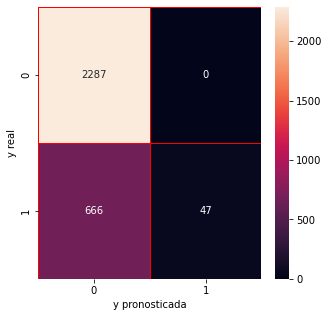

In [18]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [19]:
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.77      1.00      0.87      2287
           1       1.00      0.07      0.12       713

    accuracy                           0.78      3000
   macro avg       0.89      0.53      0.50      3000
weighted avg       0.83      0.78      0.69      3000



# Prueba de SVM con Kernel Lineal

In [38]:
clf = svm.SVC(kernel="linear", max_iter = 1000) #Eso lo ponemos porque tardó muchisimo en pensar)
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

# confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[1602,  685],
       [ 340,  373]])

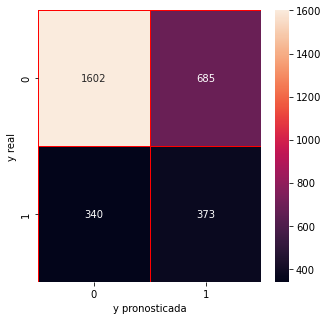

In [28]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [29]:
from sklearn.metrics import classification_report
# import itertools

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
# np.set_printoptions(precision=2)

print (classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.82      0.70      0.76      2287
           1       0.35      0.52      0.42       713

    accuracy                           0.66      3000
   macro avg       0.59      0.61      0.59      3000
weighted avg       0.71      0.66      0.68      3000



# Prueba de SVM con kernel polinomial

In [30]:
clf = svm.SVC(kernel="poly", max_iter=1000) #Eso lo ponemos porque tardó muchisimo en pensar)
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

# confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[  97, 2190],
       [  15,  698]])

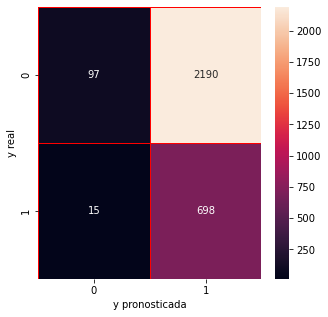

In [31]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [32]:
from sklearn.metrics import classification_report
# import itertools

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
# np.set_printoptions(precision=2)

print (classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.87      0.04      0.08      2287
           1       0.24      0.98      0.39       713

    accuracy                           0.27      3000
   macro avg       0.55      0.51      0.23      3000
weighted avg       0.72      0.27      0.15      3000



# Prueba de SVM con kernel sigmoide

In [33]:
clf = svm.SVC(kernel="sigmoid", max_iter=1000) #Eso lo ponemos porque tardó muchisimo en pensar)
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

# confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[ 872, 1415],
       [ 393,  320]])

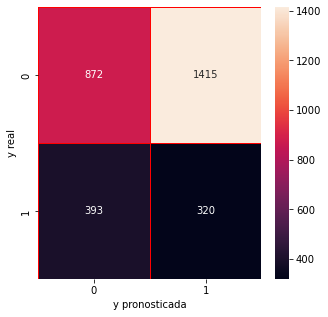

In [34]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [35]:
from sklearn.metrics import classification_report
# import itertools

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
# np.set_printoptions(precision=2)

print (classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.69      0.38      0.49      2287
           1       0.18      0.45      0.26       713

    accuracy                           0.40      3000
   macro avg       0.44      0.42      0.38      3000
weighted avg       0.57      0.40      0.44      3000



# ¿Cuál será el modelo predictivo más adecuado?
El modelo más adecuando en este caso es el del kernel rbf (Radial Basis Function o función de base radial) que es el que toma por defecto ya que tiene unas mejores estadísticas de desempeño y el score F1 más alto, con una cantidad de 78%.
Es importante decir que no es bueno para predecir empleados que renuncian, ya que tenemos 666 que el modelo predijo que se quedarían, pero renunciaron.
Este fue el mejor modelo, sin embargo, los demás kernels esstán topados a 1000 iteraciones ya que la computadora/ el programa tardaban demasiado tiempo en pensar ya que la base de datos era demasiado grande. Quizá sin un tope de máximas iteracioneslos modelos resultarían con mejores estadísticas de desempeño.

# Prediccion de un nuevo empleado

In [40]:
#Cargamos los datos del empleado
dfPred = pd.read_csv("Predrecursos_humanos.csv")
dfPred

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.87,1,5,242,5,0,1,0,sales,low


In [47]:
# Recreamos la X original para recuperar los nombres de las 18 columnas
# Quitamos 'left' y aplicamos get_dummies
X_original_nombres = pd.get_dummies(df.drop('left', axis=1), drop_first=True).columns

# Aplicamos get_dummies
nuevo_trabajador_dummies = pd.get_dummies(dfPred)

# Alineamos el nuevo empleado con las 18 columnas 
nuevo_trabajador_final = nuevo_trabajador_dummies.reindex(columns=X_original_nombres, fill_value=0)

# Entrenamos el modelo y predecimos
clf_rbf = svm.SVC(kernel="rbf")
clf_rbf.fit(X_train, y_train)
prediccion = clf_rbf.predict(nuevo_trabajador_final)

# Mostramos el resultado
print("Predicción:", prediccion[0])
if prediccion[0] == 1:
    print("El modelo RBF pronostica que el empleado SÍ RENUNCIARÁ.")
else:
    print("El modelo RBF pronostica que el empleado NO RENUNCIARÁ.")

Predicción: 0
El modelo RBF pronostica que el empleado NO RENUNCIARÁ.
